# Basic .fit file operations

In [6]:
from pathlib import Path

from garmin_fit_sdk import Decoder, Stream

ACTIVITY_PATH = Path("..") / ".." / "data" / "2026-02-26-18-00-48.fit"

In [7]:
def read_activity(path: Path) -> dict:
    decoder = Decoder(Stream.from_file(str(path)))
    messages, errors = decoder.read()

    if errors:
        raise ValueError(f"Failed to decode {path.name}: {errors}")

    return messages

In [8]:
read_activity(ACTIVITY_PATH)

{'file_id_mesgs': [{'time_created': datetime.datetime(2026, 2, 26, 17, 0, 48, tzinfo=datetime.timezone.utc),
   'product_name': ['V\x7f', '', 'y\x07\x01'],
   'manufacturer': 'zwift',
   'product': 0,
   'number': 0,
   'type': 'activity'}],
 'developer_data_id_mesgs': [{'developer_id': [0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0],
   'application_id': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
   'application_version': 0,
   'manufacturer_id': 0,
   'developer_data_index': 1}],
 'field_description_mesgs': [{'field_name': 'skin_temperature',
   'units': 'C',
   'native_mesg_num': 20,
   'developer_data_index': 1,
   'field_definition_number': 1,
   'fit_base_type_id': 132,
   'scale': 100,
   'key': 0},
  {'field_name': 'core_data_quality',
   'units': 'Q',
   'native_mesg_num': 20,
   'developer_data_index': 1,
   'field_definition_number': 2,
   'fit_base_type_id': 2,
   'key': 1},
  {'field_name': 'core_reserved'

In [27]:
import matplotlib.pyplot as plt
from math import ceil

records = read_activity(ACTIVITY_PATH).get("record_mesgs", [])
heart_rate_samples = [
    (record["timestamp"], record["heart_rate"])
    for record in records
    if record.get("timestamp") is not None and record.get("heart_rate") is not None
]

if not heart_rate_samples:
    raise ValueError("This activity contains no heart-rate samples.")

heart_rates = [heart_rate for _, heart_rate in heart_rate_samples]

In [31]:
power_samples = [
    (record["timestamp"], record["power"])
    for record in records
    if record.get("timestamp") is not None and record.get("power") is not None
]

cadence_samples = [
    (record["timestamp"], record["cadence"])
    for record in records
    if record.get("timestamp") is not None and record.get("cadence") is not None
]



In [32]:
powers = [power for _, power in power_samples]

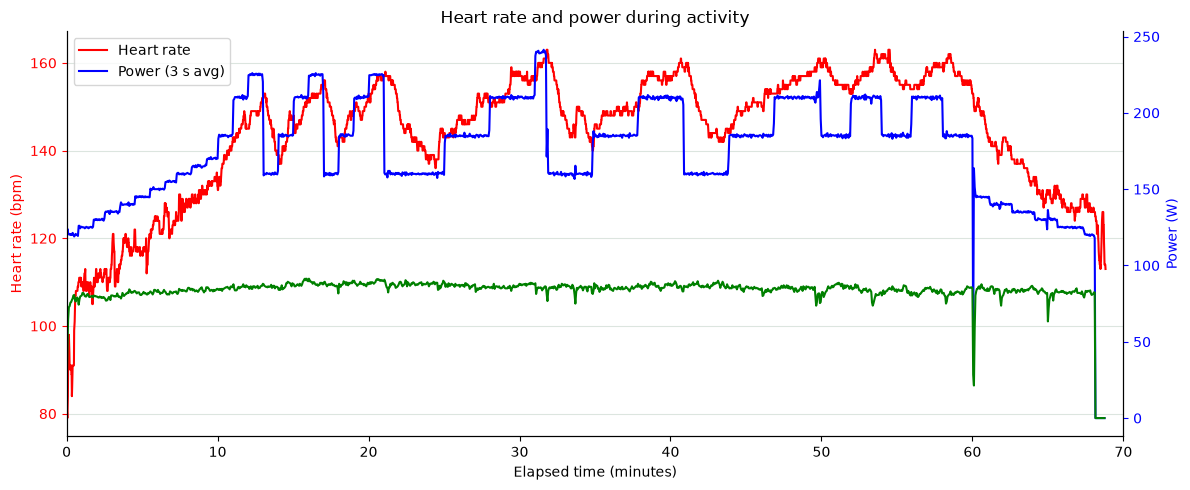

In [33]:
# calculate power as average from 3s

power_samples_3s = [
    (
        power_samples[i][0],
        sum(power for _, power in power_samples[i:i+3]) / 3
    )
    for i in range(0, len(power_samples) - 2, 3)
]

cadence_samples_3s = [
    (
        cadence_samples[i][0],
        sum(cadence for _, cadence in cadence_samples[i:i+3]) / 3
    )
    for i in range(0, len(cadence_samples) - 2, 3)
]

powers_3s = [power for _, power in power_samples_3s]
cadences_3s = [cadence for _, cadence in cadence_samples_3s]
start_time = min(heart_rate_samples[0][0], power_samples_3s[0][0])
heart_rate_minutes = [
    (timestamp - start_time).total_seconds() / 60
    for timestamp, _ in heart_rate_samples
]
power_minutes = [
    (timestamp - start_time).total_seconds() / 60
    for timestamp, _ in power_samples_3s
]
x_max = ceil(max(heart_rate_minutes[-1], power_minutes[-1]) / 10) * 10 or 10

fig, heart_rate_ax = plt.subplots(figsize=(12, 5))
power_ax = heart_rate_ax.twinx()
heart_rate_line, = heart_rate_ax.plot(
    heart_rate_minutes, heart_rates, color="red", linewidth=1.5, label="Heart rate"
)
power_line, = power_ax.plot(
    power_minutes, powers_3s, color="blue", linewidth=1.5, label="Power (3 s avg)"
)
cadence_line = power_ax.plot(
    power_minutes, cadences_3s, color="green", linewidth=1.5, label="Cadence (3 s avg)"
)
heart_rate_ax.set(
    title="Heart rate and power during activity",
    xlabel="Elapsed time (minutes)",
    ylabel="Heart rate (bpm)",
    xlim=(0, x_max),
)
power_ax.set_ylabel("Power (W)")
heart_rate_ax.set_xticks(range(0, x_max + 1, 10))
heart_rate_ax.grid(axis="y", color="#dce5df", linewidth=0.8)
heart_rate_ax.tick_params(axis="y", colors="red")
heart_rate_ax.yaxis.label.set_color("red")
power_ax.tick_params(axis="y", colors="blue")
power_ax.yaxis.label.set_color("blue")
heart_rate_ax.spines["top"].set_visible(False)
power_ax.spines["top"].set_visible(False)
heart_rate_ax.legend(
    [heart_rate_line, power_line],
    [heart_rate_line.get_label(), power_line.get_label()],
    loc="upper left",
)
fig.tight_layout()
plt.show()